Hello this is a jupyter notebook. In this next cell I will add 2 + 2

In [55]:
2+2

4

# UK solar irradiation map

This notebook creates a UK solar irradiation map from ERA5 surface solar radiation downwards data.

The process:

1. Load and inspect the ERA5 NetCDF file.
2. standardise its coordinates.
3. select the required time period.
4. crop the data to the UK.
5. convert SSRD from J/m² to kWh/m².
6. add the UK boundary.
7. display and save the finished map.

The current version uses the full ERA5 global dataset and then filters it down to the UK. An improvement will be added to download UK-only data directly

In [56]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import xarray as xr

In [57]:
ds = xr.open_dataset(INPUT_FILE)
ds

<xarray.Dataset> Size: 12kB
Dimensions:     (valid_time: 1, latitude: 49, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2026-07-01T06:00:00
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    ssrd        (valid_time, latitude, longitude) float32 11kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-18T15:26 GRIB to CDM+CF via cfgrib-0.9.1...

In [58]:
# File settings
INPUT_FILE = Path("Augdata.nc")
OUTPUT_FILE = Path("uk_irradiation_map.png")

# ERA5 settings
VARIABLE = "ssrd"
TIME_INDEX = 0

# UK map limits
UK_BOUNDS = {
    "west": -8.6,
    "east": 2.0,
    "south": 49.0,
    "north": 61.0,
}

# UK boundary data
NATURAL_EARTH_URL = (
    "https://naturalearth.s3.amazonaws.com/10m_cultural/"
    "ne_10m_admin_0_countries.zip"
)

In [59]:
print(Path.cwd())
print(INPUT_FILE)
print(INPUT_FILE.exists())

c:\Users\EllaNorman\OneDrive - Bluefield Group\Documents\IrradiationMapProject\rawdata
Augdata.nc
True


## Load and inspect the data

Opening the NetCDF file and displaying its dimensions, coordinates, variables and metadata.

In [60]:
from pathlib import Path
#just checking the file name and location is correct
list(Path("rawdata").glob("*.nc"))

[]

In [61]:
ds = xr.open_dataset(INPUT_FILE)
ds

<xarray.Dataset> Size: 12kB
Dimensions:     (valid_time: 1, latitude: 49, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2026-08-01T06:00:00
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    ssrd        (valid_time, latitude, longitude) float32 11kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-18T15:17 GRIB to CDM+CF via cfgrib-0.9.1...

## Prepare the coordinates

Standardise the latitude and longitude coordinates before selecting the UK region.

In [62]:
# Convert longitude to the -180 to 180 range and sort it
ds = ds.assign_coords(
    longitude=((ds.longitude + 180) % 360) - 180
).sortby("longitude")

# Ensure latitude runs from north to south
if float(ds.latitude[0]) < float(ds.latitude[-1]):
    ds = ds.sortby("latitude", ascending=False)

ds

<xarray.Dataset> Size: 12kB
Dimensions:     (valid_time: 1, latitude: 49, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2026-08-01T06:00:00
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    ssrd        (valid_time, latitude, longitude) float32 11kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-18T15:17 GRIB to CDM+CF via cfgrib-0.9.1...

## Select the UK irradiation data

Select the September 2026 SSRD data and crop it to the UK map area

In [63]:
# Select September 2026
irradiation = ds[VARIABLE].isel(valid_time=TIME_INDEX)

# Crop the data to the UK region
irradiation_uk = irradiation.sel(
    latitude=slice(UK_BOUNDS["north"], UK_BOUNDS["south"]),
    longitude=slice(UK_BOUNDS["west"], UK_BOUNDS["east"]),
)

irradiation_uk

<xarray.DataArray 'ssrd' (latitude: 49, longitude: 43)> Size: 8kB
[2107 values with dtype=float32]
Coordinates:
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 344B -8.5 -8.25 -8.0 -7.75 ... 1.5 1.75 2.0
    number      int64 8B ...
    valid_time  datetime64[ns] 8B 2026-08-01T06:00:00
    expver      <U4 16B ...
Attributes: (12/32)
    GRIB_paramId:                             169
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      2793
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgad
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Surface short-wave (solar) radi...
    units:                                    J m**-2
    standard_name:                            surface_downwelling_shortwave_f...
    GRIB_surface:                             0.0

## Convert the irradiation units

Convert surface solar radiation downwards from J/m² to kWh/m².

In [64]:
irradiation_kwh = irradiation_uk / 3_600_000

irradiation_kwh.attrs["units"] = "kWh/m²"

print(f"Minimum: {float(irradiation_kwh.min()):.2f} kWh/m²")
print(f"Maximum: {float(irradiation_kwh.max()):.2f} kWh/m²")
print(f"Mean: {float(irradiation_kwh.mean()):.2f} kWh/m²")

Minimum: 2.90 kWh/m²
Maximum: 5.93 kWh/m²
Mean: 4.41 kWh/m²


## Load the UK boundary

Load the United Kingdom country boundary from Natural Earth (a downloaded package)

In [65]:
world = gpd.read_file(NATURAL_EARTH_URL)

uk_boundary = world.loc[
    world["ADMIN"] == "United Kingdom"
].copy()

if uk_boundary.crs is not None and uk_boundary.crs.to_epsg() != 4326:
    uk_boundary = uk_boundary.to_crs(epsg=4326)

uk_boundary

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
78,Admin-0 country,0,2,United Kingdom,GB1,1,2,Country,1,United Kingdom,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-7.2471 55.06932, -7.25674 55...."


In [66]:
#an additional import to help with the plotting of the data
from matplotlib.colors import BoundaryNorm

## Create the UK irradiation map

Plot the September 2026 irradiation data, overlay the UK boundary and save the finished map!

Map label: August 2026
Current data range: 2.90–5.93 kWh/m²/day


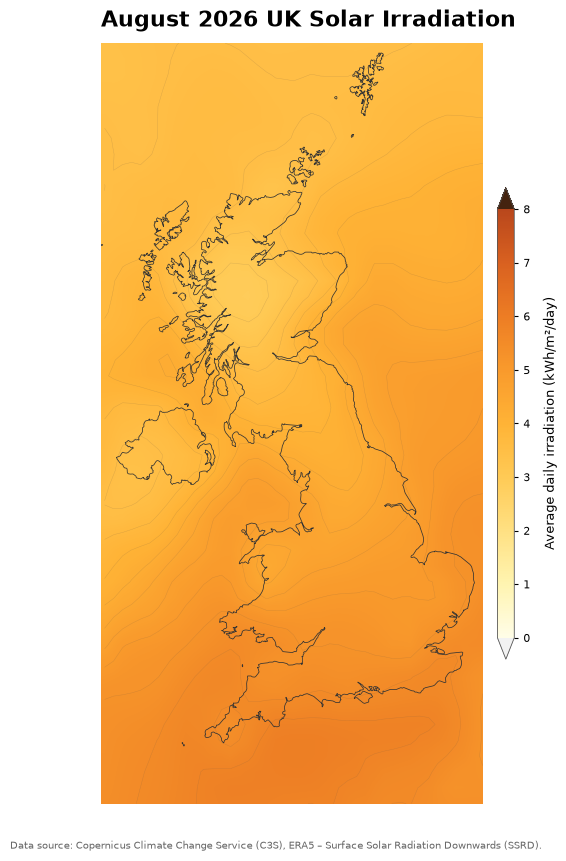

Map saved to: C:\Users\EllaNorman\uk_irradiation_map_august_2026.png


In [67]:
from matplotlib.colors import Normalize, LinearSegmentedColormap
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------
# MAP SETTINGS
# ---------------------------------------------------------

# Update this to match the dataset you have loaded
MAP_MONTH = "August 2026"

# Keep these limits unchanged across all monthly maps
FIXED_MIN = 0.0
FIXED_MAX = 8.0

# Save each month separately so previous maps are not overwritten
OUTPUT_FILE = (
    Path.home()
    / f"uk_irradiation_map_{MAP_MONTH.lower().replace(' ', '_')}.png"
)

# ---------------------------------------------------------
# COLOUR SCALE
# ---------------------------------------------------------

solar_cmap = LinearSegmentedColormap.from_list(
    "solar_gold",
    [
        "#fffde7",  # 0: very pale yellow
        "#fff4b0",  # 1: soft yellow
        "#ffe082",  # 2: golden yellow
        "#ffca55",  # 3: gold
        "#ffb336",  # 4: amber
        "#f99a2c",  # 5: light orange
        "#ed7d24",  # 6: orange
        "#d96120",  # 7: deeper orange
        "#b9471c",  # 8: burnt orange
    ],
    N=256,
)

# Make values outside the scale and missing data identifiable
solar_cmap.set_under("#f2f2f2")
solar_cmap.set_over("#44230f")
solar_cmap.set_bad("#dddddd")

norm = Normalize(
    vmin=FIXED_MIN,
    vmax=FIXED_MAX,
    clip=False,
)

# ---------------------------------------------------------
# PREPARE AND CHECK THE PLOTTING DATA
# ---------------------------------------------------------

# Ensure the array is ordered correctly for the contour layer
plot_data = irradiation_kwh.transpose("latitude", "longitude")

values = np.asarray(plot_data.values)
finite_values = values[np.isfinite(values)]

if finite_values.size == 0:
    raise ValueError(
        "The selected irradiation data contains no valid values."
    )

data_min = float(finite_values.min())
data_max = float(finite_values.max())

print(f"Map label: {MAP_MONTH}")
print(
    f"Current data range: "
    f"{data_min:.2f}–{data_max:.2f} kWh/m²/day"
)

if data_min < FIXED_MIN or data_max > FIXED_MAX:
    print(
        "Warning: some values fall outside the fixed 0–6 scale. "
        "Review the limits across all months before finalising them."
    )

# ---------------------------------------------------------
# CREATE THE MAP
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(7.2, 9))

ax.set_facecolor("#dddddd")

# Smooth irradiation layer
image = plot_data.plot.imshow(
    ax=ax,
    cmap=solar_cmap,
    norm=norm,
    interpolation="bilinear",
    add_colorbar=False,
    add_labels=False,
    x="longitude",
    y="latitude",
)

# Subtle contour lines retain regional detail
contour_levels = np.arange(
    FIXED_MIN,
    FIXED_MAX + 0.125,
    0.25,
)

# Only draw contour levels that cross the current data range
visible_levels = contour_levels[
    (contour_levels > data_min)
    & (contour_levels < data_max)
]

if visible_levels.size > 0:
    ax.contour(
        plot_data["longitude"],
        plot_data["latitude"],
        np.ma.masked_invalid(values),
        levels=visible_levels,
        colors="#705A45",
        linewidths=0.30,
        alpha=0.25,
    )

# UK coastline and boundaries
uk_boundary.boundary.plot(
    ax=ax,
    color="#333333",
    linewidth=0.55,
)

# Fixed map extent
ax.set_xlim(UK_BOUNDS["west"], UK_BOUNDS["east"])
ax.set_ylim(UK_BOUNDS["south"], UK_BOUNDS["north"])

# Remove axes
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)

# Map title
ax.set_title(
    f"{MAP_MONTH} UK Solar Irradiation",
    fontsize=16,
    fontweight="semibold",
    loc="left",
    pad=12,
)

# ---------------------------------------------------------
# COLOUR BAR
# ---------------------------------------------------------

colourbar = fig.colorbar(
    image,
    ax=ax,
    shrink=0.62,
    aspect=28,
    pad=0.025,
    ticks=np.arange(FIXED_MIN, FIXED_MAX + 0.5, 1.0),
    extend="both",
)

colourbar.set_label(
    "Average daily irradiation (kWh/m²/day)",
    fontsize=9,
    labelpad=9,
)

colourbar.ax.tick_params(
    labelsize=8,
    length=3,
)

colourbar.outline.set_edgecolor("#555555")
colourbar.outline.set_linewidth(0.6)

# ---------------------------------------------------------
# SOURCE AND LAYOUT
# ---------------------------------------------------------

fig.text(
    0.08,
    0.025,
    "Data source: Copernicus Climate Change Service (C3S), "
    "ERA5 – Surface Solar Radiation Downwards (SSRD).",
    fontsize=7,
    color="#666666",
    ha="left",
)

fig.subplots_adjust(
    left=0.06,
    right=0.88,
    top=0.92,
    bottom=0.075,
)

# ---------------------------------------------------------
# SAVE AND DISPLAY
# ---------------------------------------------------------

fig.savefig(
    str(OUTPUT_FILE),
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print(f"Map saved to: {OUTPUT_FILE}")